# Mouse lung demo: cell–ECM contacts and cellular context

**Estimated runtime: 2–5 minutes on a modern CPU with eight threads**,
excluding installation and the first dataset download.
**Measured runtime: 32 s** with eight CPU threads and no GPU, using cached downloads.

Load six mouse-lung ROIs, create ECM patches, build the cell–ECM graph,
measure airway epithelial cell (AEC) contacts, and reconstruct corrupted
ECM labels from cellular context. **Seed 0, fixed selected settings and
one held-out mouse. No CNN or parameter search is required.**

This is a fresh-fit demonstration. The full paper's saved partitions,
two mouse-held-out folds and five corruption realisations are in the
reproducibility repository. Keep `lung_demo_helpers.py` beside this notebook.

## Setup

In Colab, keep the default **Latest** CPU runtime. Run setup,
restart when requested, then run all cells.
Locally, install `lung_demo_requirements.txt` in Python 3.11/3.12/3.13 and keep
the helper beside the notebook.


In [1]:
import importlib.util
try:
    in_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    in_colab = False

if in_colab:
    from pathlib import Path
    from urllib.request import urlretrieve
    if not Path("colab_setup.py").exists():
        urlretrieve("https://raw.githubusercontent.com/moeghaf/mantpy_reproducibility/main/notebooks/demos/colab_setup.py", "colab_setup.py")
    from colab_setup import prepare_colab
    prepare_colab("lung")


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mantpy as mt
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits
from lung_demo_helpers import (
    plot_patch_map, patch_grid, aec_contact_mask, cell_context_features,
    mixed_corruption, reconstruction_metrics,
)

SEED = 0
PATCH_SIZE = 10
WALL_CLUSTER = 1
threadpool_limits(limits=8)
np.random.seed(SEED)


<python-environment>/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load the cohort and visualise one ROI

The public loader supplies raw images, typed-cell AnnData objects,
the acquisition panel and the six-ROI/two-mouse metadata.


In [3]:
bundle = mt.datasets.balbc_pbs_lung(cache_dir=Path("data"))
cells = bundle.cohort_cells
SHOWCASE = bundle.showcase_roi
panel = bundle.panel.loc[bundle.panel["keep"].eq(1)].reset_index(drop=True)
FN_INDEX = int(panel.index[panel["name"].eq("Fibronectin")][0])
assert len(cells) == 6 and bundle.metadata["Mouse"].nunique() == 2
bundle.metadata[["sample_id", "Mouse", "strain", "treatment"]]


,sample_id,Mouse,strain,treatment
0,roi_001,mouse_01,BALB/c,PBS
1,roi_002,mouse_01,BALB/c,PBS
2,roi_003,mouse_01,BALB/c,PBS
3,roi_004,mouse_02,BALB/c,PBS
4,roi_005,mouse_02,BALB/c,PBS
5,roi_006,mouse_02,BALB/c,PBS


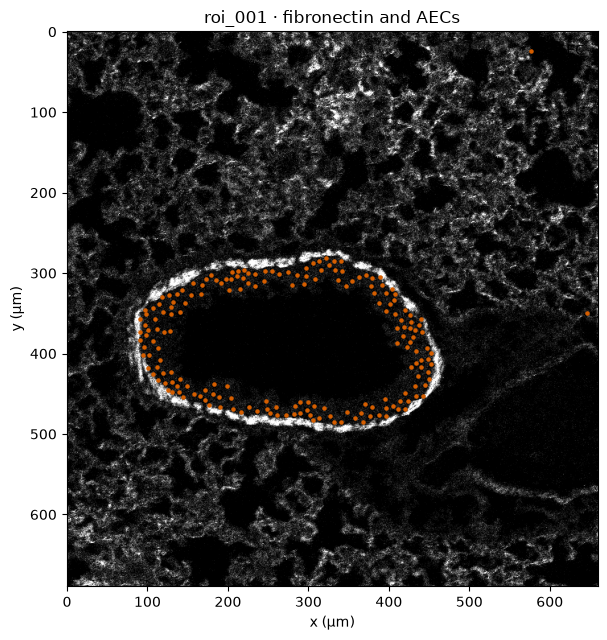

In [4]:
raw_fn = np.asarray(bundle.images[SHOWCASE][FN_INDEX], dtype=float)
vmax = np.percentile(raw_fn[raw_fn > 0], 99)
aec = cells[SHOWCASE].obs["cell_type"].astype(str).eq("AEC").to_numpy()
xy = cells[SHOWCASE].obsm["spatial"]
plt.figure(figsize=(6.5, 6.5))
plt.imshow(raw_fn, cmap="gray", vmin=0, vmax=vmax)
plt.scatter(xy[aec, 0], xy[aec, 1], s=5, c="#D55E00", label="AEC")
plt.title(f"{SHOWCASE} · fibronectin and AECs")
plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


## 2. Shared preprocessing and ECM clustering

Standardise each ECM marker across all six images, then calculate marker
means in non-overlapping 10 × 10-pixel patches. Fit four K-means components,
remove the dimmest as background and order the three signal clusters by size.


In [5]:
ecm = mt.pp.ecm_patches_from_images(
    bundle.images, bundle.panel, normalize="pooled_zscore",
    patch_size=PATCH_SIZE, features=["mean"],
    ecm_K=None, background_quantile=0.0,
)
clustering = mt.pp.cluster_ecm_patches(
    ecm, n_clusters=4, method="kmeans", subset="all",
    random_state=SEED, n_init=10,
)
background = mt.pp.remove_background_patches(
    ecm, clustering, background="lowest_mean", order_signal_by="size",
)
tables = {sample: carrier.uns["ecm_patches"] for sample, carrier in ecm.items()}
total = sum(len(p) for p in tables.values())
signal = sum(p["ecm_cluster"].ge(0).sum() for p in tables.values())
print(f"{total:,} total patches; {signal:,} signal patches.")
print(background)


27,324 total patches; 11,451 signal patches.
ECM background removal
  component 1 -> background (-1): 15,873 patches
  ECM 0: 8,655 patches
  ECM 1: 1,480 patches
  ECM 2: 1,316 patches


## 3. Inspect the ECM clusters

Marker profiles and location support the descriptions ECM 0, alveolar;
ECM 1, bronchovascular wall; and ECM 2, adventitial. The stored paper
partition has 11,435 signal patches; this fresh K-means fit reports its
own patch count above.


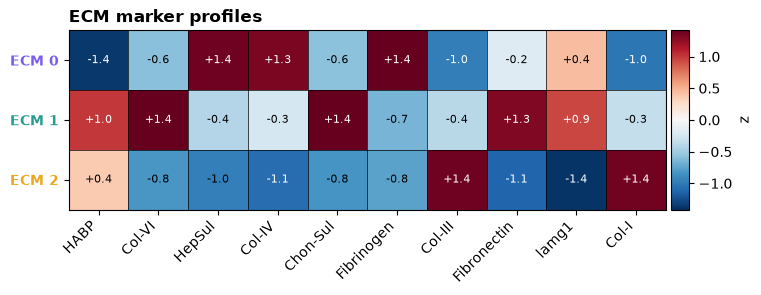

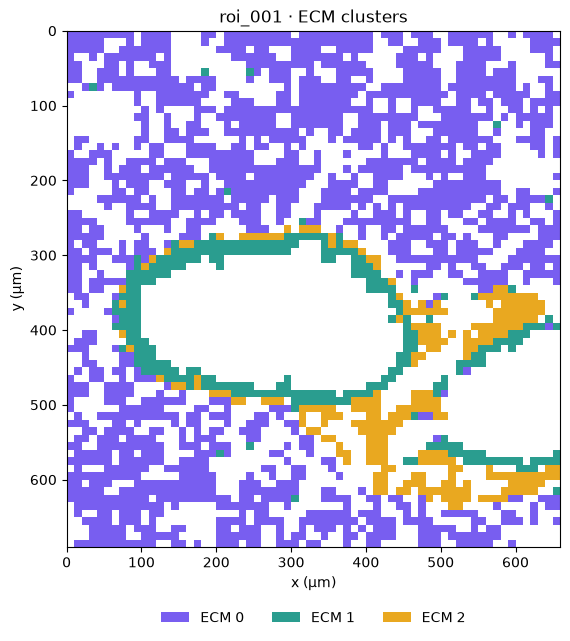

In [6]:
mt.pl.ecm_centroid_heatmap(
    ecm, ecm_names=bundle.ecm_names, K_ecm=3,
    cluster_colors=bundle.ecm_palette, title="ECM marker profiles",
    figsize=(8, 4),
)
plot_patch_map(
    tables[SHOWCASE], f"{SHOWCASE} · ECM clusters", palette=bundle.ecm_palette,
)


## 4. Build the three graph layers

Cell–cell edges have a 15-pixel radius. ECM edges follow the eight-connected
patch grid. Each cell joins its five nearest patches within 15 pixels.
Background patches remain unlabelled nodes and are excluded from counts.


In [7]:
mt.pp.attach_ecm_patches(cells, ecm)
graph_result = mt.gr.build_cell_ecm_graphs(
    cells, cell_graph="squidpy", cell_radius=(0, 15),
    ecm_edge_method="grid", ecm_grid_connectivity=8,
    cell_ecm_edge_method="knn", cell_ecm_k=5, cell_ecm_Dmax=15,
)
graph_counts = pd.DataFrame([vars(row) for row in graph_result.summaries])
graph_counts


<python-environment>/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
<python-environment>/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
<python-environment>/site-packages/mantpy/gr.py:1640: FutureWarning: Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.
  sq.gr.spatial_neighbors(adata, **sq_kwargs)
<python-environment>/site-packages/mantpy/gr.py:1640: FutureWarning: Parameter `n_neighs` is ignored when `radius` is set use `spatial_neighbors_radius` instead.
  sq.gr.spatial_neighbors(adata, **sq_kwargs)
<python-environment>/site-packages/mantpy/gr.py:1640: FutureWarning: Calling `spatial_neighbors` is depre

,sample,n_nodes,n_cells,n_ecm,cell_cell_edges,ecm_ecm_edges,cell_ecm_edges
0,roi_001,6374,1820,4554,3029,17813,9046
1,roi_002,6457,1903,4554,3308,17813,9450
2,roi_003,6516,1962,4554,3248,17813,9739
3,roi_004,6496,1942,4554,3861,17813,9639
4,roi_005,6378,1824,4554,3261,17813,9043
5,roi_006,6351,1797,4554,2812,17813,8914


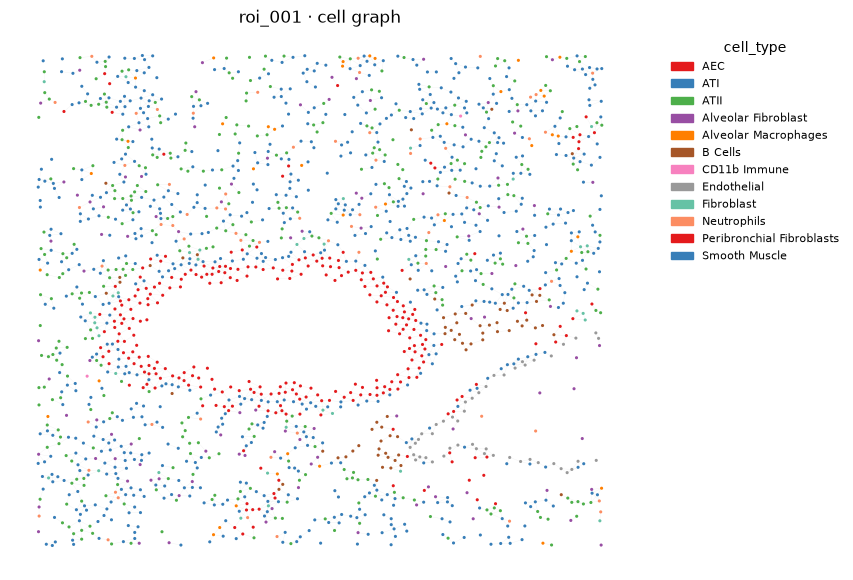

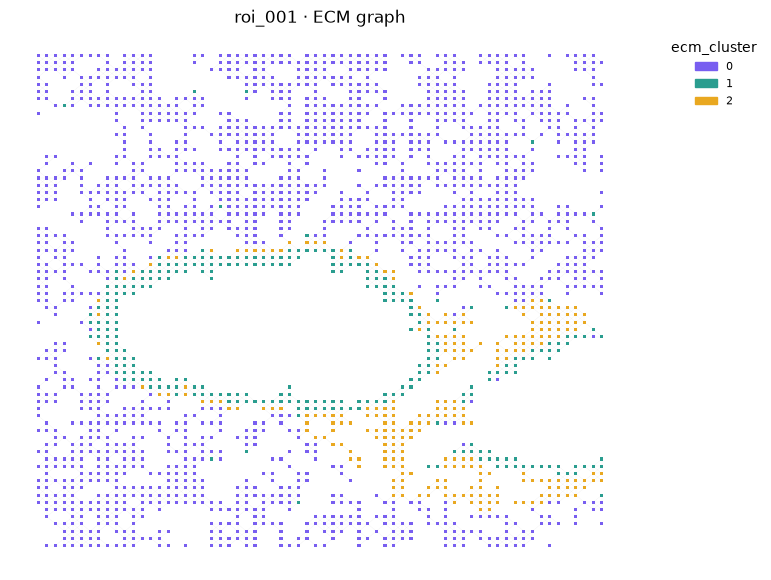

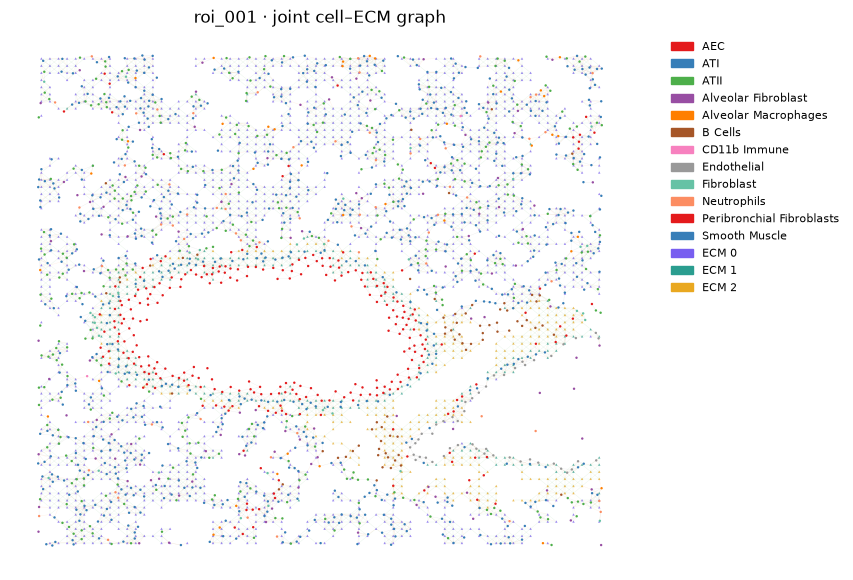

In [8]:
ax = mt.pl.cell_graph(
    cells[SHOWCASE], node_size=5, node_edgecolor=None,
    node_linewidth=0, edge_alpha=0.15, edge_width=0.3,
    ax_off=True, show=False,
)
ax.set_title(f"{SHOWCASE} · cell graph")
plt.show()
ax = mt.pl.ecm_graph(
    cells[SHOWCASE], node_size=5, node_marker="s", node_edgecolor=None,
    node_linewidth=0, edge_alpha=0.15, edge_width=0.3,
    palette=bundle.ecm_palette, ax_off=True, show=False,
)
ax.set_title(f"{SHOWCASE} · ECM graph")
plt.show()
ax = mt.pl.cell_ecm_graph(
    cells[SHOWCASE], node_size_cell=3, node_size_ecm=3,
    node_edgecolor=None, node_linewidth=0, edge_alpha=0.1, edge_width=0.3,
    ecm_palette=bundle.ecm_palette, ax_off=True, show=False,
)
ax.set_title(f"{SHOWCASE} · joint cell–ECM graph")
plt.show()


## 5. Which ECM does an AEC contact?

Count AEC–ECM edges and compare them with the expected counts from each
ROI's edge frequencies. Pool observed and expected counts across ROIs.
These descriptive results use no permutation test.


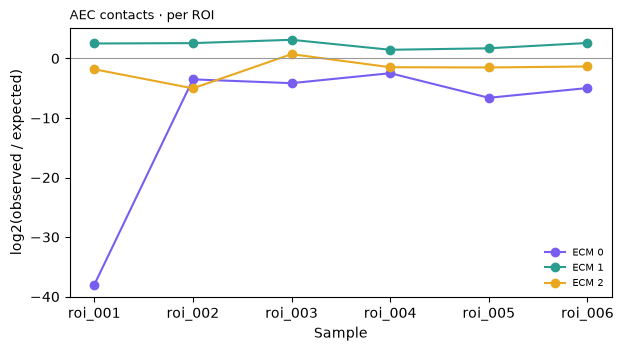

,cluster,n_obs,n_exp,log2_enr
0,0,150,1908.109739,-3.669110
1,1,2505,603.281354,2.053908
2,2,75,218.608907,-1.543390


In [9]:
enrichment = mt.tl.cell_ecm_enrichment(
    cells, "AEC", K_ecm=3, n_perm=0, random_state=SEED,
)
per_roi_enrichment = cells[SHOWCASE].uns["cell_ecm_enrichment_per_roi"]
ax = mt.pl.cell_ecm_enrichment_per_roi(
    per_roi_enrichment, cluster_colors=bundle.ecm_palette,
    title="AEC contacts · per ROI", figsize=(7, 3.5),
)
enrichment[["cluster", "n_obs", "n_exp", "log2_enr"]]


## 6. Marker profiles of AEC-contacted bronchovascular matrix

Count each patch once. Within ECM 1, subtract the marker mean of patches
without an AEC edge from the mean of patches with one. Calculate the
contrast separately for each ROI, then average the six ROIs equally.


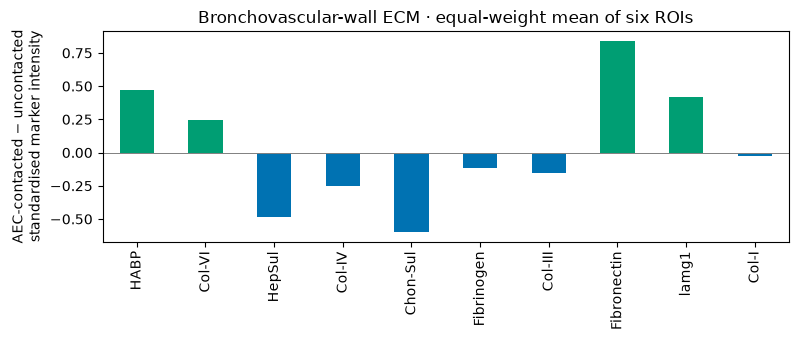

,HABP,Col-VI,HepSul,Col-IV,Chon-Sul,Fibrinogen,Col-III,Fibronectin,lamg1,Col-I
roi_001,0.404,0.457,-0.375,-0.185,-1.027,-0.101,-0.232,1.047,0.667,-0.036
roi_002,0.242,0.961,-0.371,-0.189,-0.592,-0.108,-0.289,2.313,0.988,-0.034
roi_003,0.793,-0.535,-0.440,-0.760,0.179,-0.433,0.055,0.117,0.012,0.138
roi_004,0.519,-0.129,-0.519,-0.107,-0.716,-0.007,-0.256,0.263,0.092,-0.224
roi_005,0.332,0.508,-0.471,-0.034,-1.185,-0.008,-0.036,0.660,0.395,0.040
roi_006,0.523,0.190,-0.716,-0.251,-0.247,-0.062,-0.186,0.643,0.338,-0.046


In [10]:
feature_columns = [f"feat_{i}" for i in range(len(bundle.ecm_names))]
contacts = {sample: aec_contact_mask(adata) for sample, adata in cells.items()}
contrasts = {}
for sample, patches in tables.items():
    wall = patches["ecm_cluster"].eq(WALL_CLUSTER).to_numpy()
    linked = contacts[sample]
    with_aec = patches.loc[wall & linked, feature_columns].mean()
    without_aec = patches.loc[wall & ~linked, feature_columns].mean()
    contrasts[sample] = (with_aec - without_aec).to_numpy()
marker_contrasts = pd.DataFrame.from_dict(
    contrasts, orient="index", columns=bundle.ecm_names,
)
mean_contrast = marker_contrasts.mean(axis=0)
mean_contrast.plot.bar(
    figsize=(8, 3.5), color=np.where(mean_contrast >= 0, "#009E73", "#0072B2"),
)
plt.axhline(0, color="gray", linewidth=0.7)
plt.ylabel("AEC-contacted − uncontacted\nstandardised marker intensity")
plt.title("Bronchovascular-wall ECM · equal-weight mean of six ROIs")
plt.tight_layout()
plt.show()
marker_contrasts.round(3)


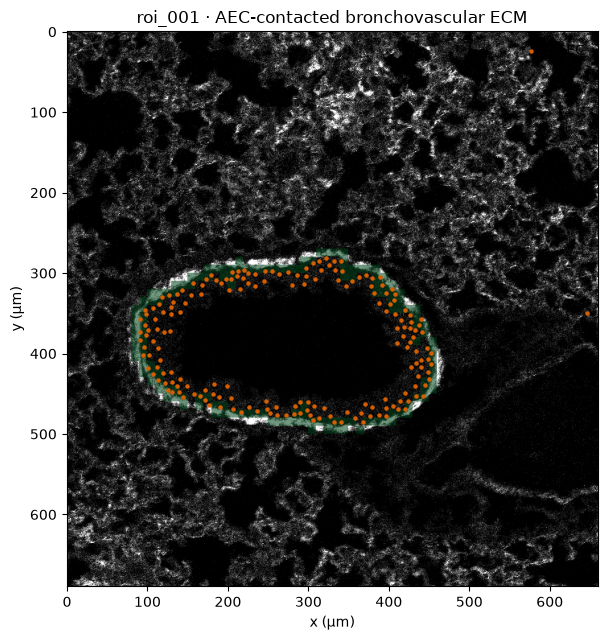

In [11]:
patches = tables[SHOWCASE]
selected = contacts[SHOWCASE] & patches["ecm_cluster"].eq(WALL_CLUSTER).to_numpy()
grid = patch_grid(patches, selected.astype(float), PATCH_SIZE)
overlay = np.repeat(np.repeat(grid, PATCH_SIZE, axis=0), PATCH_SIZE, axis=1)
plt.figure(figsize=(6.5, 6.5))
plt.imshow(raw_fn, cmap="gray", vmin=0, vmax=vmax)
plt.imshow(
    np.ma.masked_where(overlay < 0.5, overlay), cmap="Greens",
    vmin=0, vmax=1, alpha=0.55,
)
plt.scatter(xy[aec, 0], xy[aec, 1], s=5, c="#D55E00", label="AEC")
plt.title(f"{SHOWCASE} · AEC-contacted bronchovascular ECM")
plt.xlabel("x (µm)")
plt.ylabel("y (µm)")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


## 7. Reconstruct labels from cell context: one held-out mouse

Hold out mouse 01 and train on mouse 02's three pristine ROIs. Use the
selected mouse-01 cell-context configuration: cell-type counts weighted
by Gaussian distance on a 15-pixel cell–ECM radius graph, one hop, and an
elastic-net multinomial logistic model. ECM labels never enter its features.


In [12]:
HELD_OUT_MOUSE = "mouse_01"
mouse_by_roi = bundle.metadata.set_index("sample_id")["Mouse"].astype(str)
train_rois = [sample for sample in cells if mouse_by_roi[sample] != HELD_OUT_MOUSE]
test_rois = [sample for sample in cells if mouse_by_roi[sample] == HELD_OUT_MOUSE]
assert len(train_rois) == len(test_rois) == 3
print("Training ROIs:", train_rois)
print("Held-out ROIs:", test_rois)

# Rebuild the selected reconstruction graph after the descriptive analysis.
context_graph = mt.gr.build_cell_ecm_graphs(
    cells, cell_graph="mantpy", cell_edge_method="radius", cell_radius=15,
    ecm_edge_method="grid", ecm_grid_connectivity=8,
    cell_ecm_edge_method="radius", cell_ecm_r=15,
)
cell_types = sorted(set().union(*[
    set(adata.obs["cell_type"].astype(str)) for adata in cells.values()
]))
X_context = {
    sample: cell_context_features(adata, cell_types, edge_weight="gaussian_median")
    for sample, adata in cells.items()
}


Training ROIs: ['roi_004', 'roi_005', 'roi_006']
Held-out ROIs: ['roi_001', 'roi_002', 'roi_003']


In [13]:
train_signal = {sample: tables[sample]["ecm_cluster"].ge(0).to_numpy()
                for sample in train_rois}
X_train = np.vstack([X_context[sample][train_signal[sample]] for sample in train_rois])
y_train = np.concatenate([
    tables[sample].loc[train_signal[sample], "ecm_cluster"].to_numpy(int)
    for sample in train_rois
])
classifier = LogisticRegression(
    C=1.1100720432026485, penalty="elasticnet",
    l1_ratio=0.9158779086499104, solver="saga",
    max_iter=200, tol=0.001, class_weight=None, random_state=SEED,
).fit(X_train, y_train)
assert np.array_equal(classifier.classes_, np.arange(3))
print(f"Fitted on {len(y_train):,} pristine signal patches.")


Fitted on 4,294 pristine signal patches.


## 8. Corrupt, detect and reconstruct

Replace 10% of each held-out ROI's signal labels: half in square blocks
of 50, 100 or 150 pixels and half as isolated replacements. Use one seed-0
realisation, with deterministic ROI sub-seeds. Relabel when the observed
label's negative log-probability exceeds 2.9922 and the predicted class has
probability at least 0.5.


In [14]:
reconstruction = {}
metric_rows = []
for sample in test_rois:
    patches = tables[sample]
    pristine = patches["ecm_cluster"].to_numpy(int)
    roi_seed = SEED * 1000 + list(cells).index(sample)
    observed, changed, blocks = mixed_corruption(
        patches[["x", "y"]].to_numpy(), pristine, seed=roi_seed,
        fraction=0.1, block_sides=(50, 100, 150), min_block_patches=20,
    )
    proba = classifier.predict_proba(X_context[sample])
    signal_mask = pristine >= 0
    anomaly = np.zeros(len(pristine))
    rows = np.flatnonzero(signal_mask)
    anomaly[rows] = -np.log(np.maximum(proba[rows, observed[rows]], 1e-12))
    prediction = proba.argmax(axis=1)
    replace = (signal_mask & (prediction != observed)
               & (anomaly >= 2.9922106433676467) & (proba.max(axis=1) >= 0.5))
    cleaned = observed.copy()
    cleaned[replace] = prediction[replace]
    reconstruction[sample] = dict(
        pristine=pristine, observed=observed, cleaned=cleaned,
        changed=changed, anomaly=anomaly, blocks=blocks,
    )
    metric_rows.append({"ROI": sample, **reconstruction_metrics(
        pristine, observed, cleaned, changed, anomaly,
    )})
metrics = pd.DataFrame(metric_rows).set_index("ROI")
metrics.round(4)


,signal_patches,replaced_patches,detection_ROC_AUC,replaced_label_recovery,uncorrupted_error,accuracy_before,accuracy_after
ROI,,,,,,,
roi_001,2268,227,0.9570,0.6211,0.0196,0.8999,0.9444
roi_002,2418,242,0.9715,0.8017,0.0312,0.8999,0.9520
roi_003,2471,247,0.9923,0.8219,0.0076,0.9000,0.9753


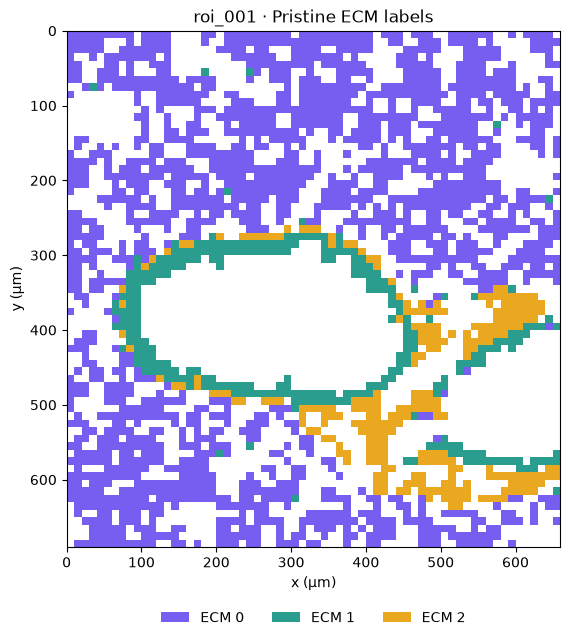

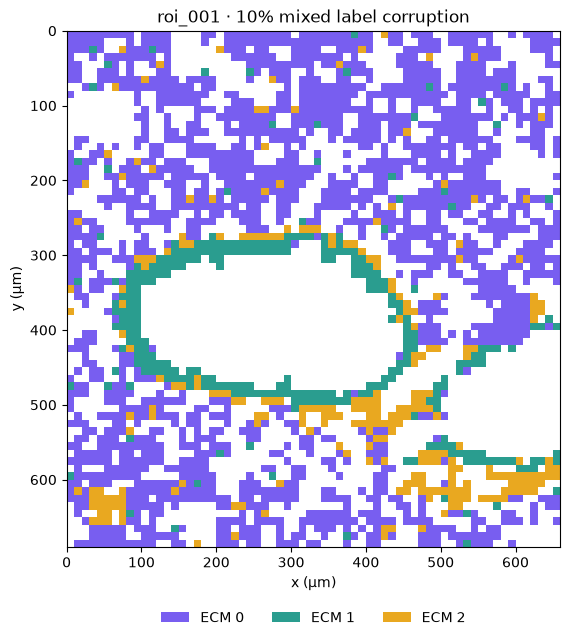

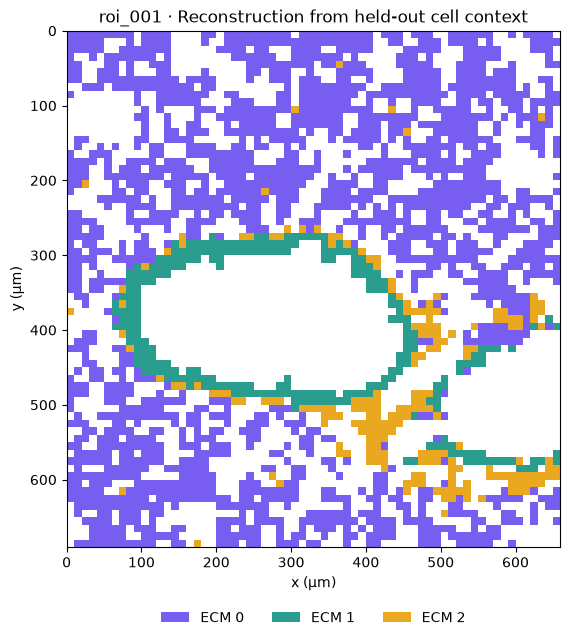

In [15]:
DEMO_ROI = test_rois[0]
for name, title in (
    ("pristine", "Pristine ECM labels"),
    ("observed", "10% mixed label corruption"),
    ("cleaned", "Reconstruction from held-out cell context"),
):
    plot_patch_map(
        tables[DEMO_ROI], f"{DEMO_ROI} · {title}",
        labels=reconstruction[DEMO_ROI][name], palette=bundle.ecm_palette,
    )


## Save the demo results

Export row-aligned patch labels and coordinates, descriptive statistics
and the held-out reconstruction metrics.


In [16]:
result_dir = Path("demo_results")
result_dir.mkdir(exist_ok=True)
partition_frames = []
for sample, patches in tables.items():
    frame = patches.copy()
    frame.insert(0, "ROI", sample)
    frame.insert(1, "mouse", mouse_by_roi[sample])
    if sample in reconstruction:
        frame["observed_label"] = reconstruction[sample]["observed"]
        frame["reconstructed_label"] = reconstruction[sample]["cleaned"]
        frame["is_replaced"] = reconstruction[sample]["changed"]
    partition_frames.append(frame)
pd.concat(partition_frames, ignore_index=True).to_csv(result_dir / "lung_patches.csv", index=False)
enrichment.to_csv(result_dir / "aec_enrichment.csv", index=False)
per_roi_enrichment.to_csv(result_dir / "aec_enrichment_per_roi.csv", index=False)
marker_contrasts.to_csv(result_dir / "aec_marker_contrasts.csv")
graph_counts.to_csv(result_dir / "descriptive_graph_counts.csv", index=False)
metrics.to_csv(result_dir / "reconstruction_metrics.csv")
(result_dir / "lung_demo_summary.json").write_text(json.dumps({
    "seed": SEED, "ROIs": len(cells), "mice": int(mouse_by_roi.nunique()),
    "total_patches": int(total), "signal_patches": int(signal),
    "held_out_mouse": HELD_OUT_MOUSE,
    "train_ROIs": train_rois, "test_ROIs": test_rois,
    "description": "Fresh fits; one selected mouse-held-out cell-context model and one corruption realisation.",
}, indent=2))
print(f"Saved results in {result_dir.resolve()}")


Saved results in demo_results/
